# Regrid MODIS (MCD12Q1 500m, sinusoidal) to 0.1deg cropland mask

this crop filter is used for both 2024 and 2025

In [5]:
import numpy as np
import pandas as pd
from pyhdf.SD import SD, SDC
from pyproj import Transformer, CRS
from pathlib import Path

## MODIS sinusoidal tile geometry
the MODIS sinusoidal projection = a flat map where positions are in metres (x, y) instead of degrees. 

- +proj=sinu : the sinusoidal projection
- +lon_0=0: centred on the prime meridian
- +x_0=0 +y_0=0: no offsets, x = 0, y = 0 is where the equator meets 0° longitude
- +R=6371007.181: Earth radius in metres 
- +units=m: coordinates in metres
- +no_defs: don't add any default settings

In [6]:
MODIS_SINU_CRS = CRS.from_proj4('+proj=sinu +lon_0=0 +x_0=0 +y_0=0 +R=6371007.181 +units=m +no_defs')
WGS84_CRS = CRS.from_epsg(4326)
transformer = Transformer.from_crs(MODIS_SINU_CRS, WGS84_CRS, always_xy=True)
TILE_SIZE_M = 1111950.519667  # meters per 10x10deg tile
PIXELS_PER_TILE = 2400 # 500m product, 2400x2400 pixels per tile
PIXEL_SIZE_M = TILE_SIZE_M / PIXELS_PER_TILE
GLOBAL_X_MIN = -20015109.354 #(-R*pi)
GLOBAL_Y_MAX = 10007554.677 # (R*pi/2)

In [7]:
tile_dir = Path('/global/scratch/users/rubypercival/MODIS24') 
tile_files = sorted(tile_dir.glob('MCD12Q1.A2024001.h*.hdf'))
print(f'Found {len(tile_files)} tiles')
for f in tile_files:
    print(f)    

Found 6 tiles
/global/scratch/users/rubypercival/MODIS24/MCD12Q1.A2024001.h09v05.061.2025205021705.hdf
/global/scratch/users/rubypercival/MODIS24/MCD12Q1.A2024001.h10v04.061.2025205021704.hdf
/global/scratch/users/rubypercival/MODIS24/MCD12Q1.A2024001.h10v05.061.2025205034838.hdf
/global/scratch/users/rubypercival/MODIS24/MCD12Q1.A2024001.h11v04.061.2025205064738.hdf
/global/scratch/users/rubypercival/MODIS24/MCD12Q1.A2024001.h11v05.061.2025205063608.hdf
/global/scratch/users/rubypercival/MODIS24/MCD12Q1.A2024001.h12v04.061.2025205083359.hdf


In [8]:
def read_tile(hdf_path):
    parts = hdf_path.name.split('.')
    hv = [p for p in parts if p.startswith('h') and 'v' in p][0]
    h = int(hv[1:3])
    v = int(hv[4:6])
    file = SD(str(hdf_path), SDC.READ)
    sds_obj = file.select('LC_Type1')
    data = sds_obj.get()  # shape(2400, 2400)

    # sinusoidal x/y for the upper-left corner of this tile
    tile_x_min = GLOBAL_X_MIN + h * TILE_SIZE_M
    tile_y_max = GLOBAL_Y_MAX - v * TILE_SIZE_M

    rows, cols = np.meshgrid(np.arange(PIXELS_PER_TILE), np.arange(PIXELS_PER_TILE), indexing='ij')

    # sinusoidal x/y at each pixel's center
    x_sinu = tile_x_min + (cols + 0.5) * PIXEL_SIZE_M
    y_sinu = tile_y_max - (rows + 0.5) * PIXEL_SIZE_M

    lon, lat = transformer.transform(x_sinu.ravel(), y_sinu.ravel())

    df = pd.DataFrame({
        'lat': lat,
        'lon': lon,
        'land_cover': data.ravel()})
    return df

In [9]:
tile_dfs = []
for f in tile_files:
    print('Reading', f.name)
    tile_dfs.append(read_tile(f))
df = pd.concat(tile_dfs, ignore_index=True)
print(f'Total pixels across all tiles: {len(df):,}')

Reading MCD12Q1.A2024001.h09v05.061.2025205021705.hdf
Reading MCD12Q1.A2024001.h10v04.061.2025205021704.hdf
Reading MCD12Q1.A2024001.h10v05.061.2025205034838.hdf
Reading MCD12Q1.A2024001.h11v04.061.2025205064738.hdf
Reading MCD12Q1.A2024001.h11v05.061.2025205063608.hdf
Reading MCD12Q1.A2024001.h12v04.061.2025205083359.hdf
Total pixels across all tiles: 34,560,000


In [10]:
lon_min, lon_max = -104, -80
lat_min, lat_max = 36, 49

df = df[df['land_cover'] >= 0]  # drop fill values
df = df[
    (df['lon'] >= lon_min) & (df['lon'] <= lon_max) &
    (df['lat'] >= lat_min) & (df['lat'] <= lat_max)]

df['is_cropland'] = (df['land_cover'] == 12).astype(int)  # MODIS IGBP class 12 = Croplands
print(f'Pixels within bounding box: {len(df):,}')

Pixels within bounding box: 13,221,340


In [11]:
df['grid_lat'] = (np.floor(df['lat'] / 0.1) * 0.1 + 0.05).astype('float64').round(2)
df['grid_lon'] = (np.floor(df['lon'] / 0.1) * 0.1 + 0.05).astype('float64').round(2)

In [12]:
agg = df.groupby(['grid_lat', 'grid_lon'])['is_cropland'].agg(count='count', cropland_sum='sum').reset_index()
agg['cropland_fraction'] = agg['cropland_sum'] / agg['count']

cropland_grid = agg[agg['cropland_fraction'] >= 0.6].copy()
cropland_grid['is_majority_cropland'] = True

cropland_mask_q1 = cropland_grid[['grid_lat', 'grid_lon', 'is_majority_cropland']]
print('Total cropland cells (MCD12Q1):', cropland_mask_q1.shape[0])
print('Average pixels contributing per output cell:', agg['count'].mean())
cropland_mask_q1.head()

Total cropland cells (MCD12Q1): 10995
Average pixels contributing per output cell: 423.76089743589745


,grid_lat,grid_lon,is_majority_cropland
11,36.05,-102.85,True
12,36.05,-102.75,True
13,36.05,-102.65,True
14,36.05,-102.55,True
15,36.05,-102.45,True


In [13]:
output_file = '/global/scratch/users/rubypercival/MODIS24/0.1x0.1_cropland_mask_MCD12Q1'
cropland_mask_q1.to_parquet(output_file, engine='pyarrow')
print('Saved to:', output_file)

Saved to: /global/scratch/users/rubypercival/MODIS24/0.1x0.1_cropland_mask_MCD12Q1


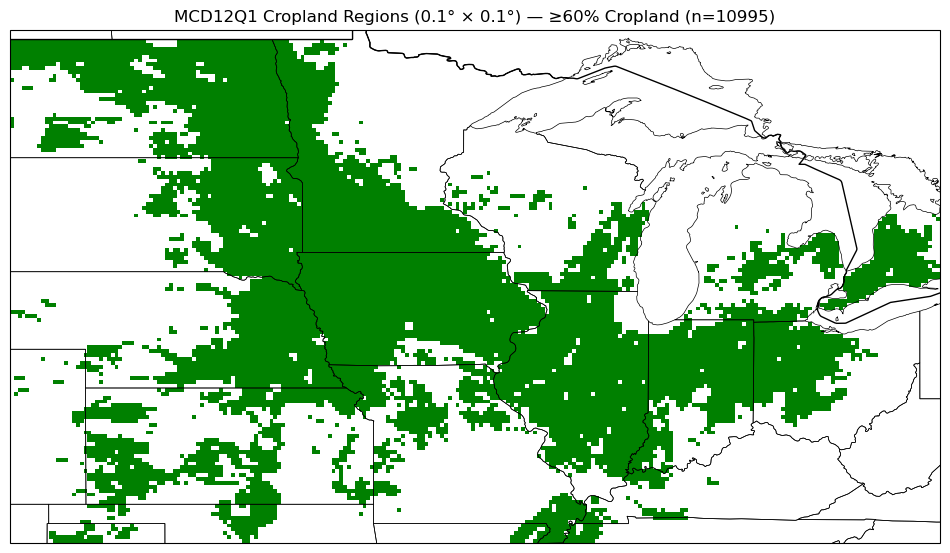

In [14]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
# Rectangle from matplotlib requires the bottom left corner, hence subtracting 0.05 from lat and lon

fig = plt.figure(figsize=(12,8))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.set_extent([-104, -80, 36, 49])

for _, row in cropland_mask_q1.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),
        0.1, 0.1, facecolor='green', linewidth=0.1, transform=ccrs.PlateCarree())
    ax.add_patch(rect)

plt.title(f"MCD12Q1 Cropland Regions (0.1° × 0.1°) — ≥60% Cropland (n={len(cropland_mask_q1)})")
plt.show()